# Movie Recommender System

Comparing several recommendation approaches on the **MovieLens `ml-latest-small`** dataset
(~100k ratings, 610 users, ~9.7k movies):

1. Baselines (global mean, user mean)
2. User-based collaborative filtering
3. Item-based collaborative filtering
4. SVD matrix factorization
5. Neural collaborative filtering (Keras)
6. A simple hybrid (average of the models)

All models share the same 80/20 split and are compared by **RMSE on the held-out test ratings**.

> The dataset is read from a local copy of `ml-latest-small` (see section 1).

In [ ]:
 %pip install -q pandas numpy matplotlib scikit-learn tensorflow

In [ ]:
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

## 1. Load the data

Place `ml-latest-small.zip` or the extracted `ml-latest-small/` folder next to this notebook
(on Colab: upload it via the Files panel).

In [ ]:
DATA_PATHS = ["ml-latest-small", "ml-latest-small.zip", "data/ml-latest-small", "data/ml-latest-small.zip"]


def load_movielens():
    path = next((p for p in DATA_PATHS if os.path.exists(p)), None)
    if path is None:
        raise FileNotFoundError(f"MovieLens not found. Looked for: {DATA_PATHS}")
    if os.path.isdir(path):
        ratings = pd.read_csv(os.path.join(path, "ratings.csv"))
        movies = pd.read_csv(os.path.join(path, "movies.csv"))
    else:
        with zipfile.ZipFile(path) as z:
            ratings = pd.read_csv(z.open("ml-latest-small/ratings.csv"))
            movies = pd.read_csv(z.open("ml-latest-small/movies.csv"))
    return ratings.rename(columns={"userId": "user_id", "movieId": "item_id"}), movies


df, movies = load_movielens()
titles = movies.set_index("movieId")["title"]
df.head()

,user_id,item_id,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Ratings: 100836 | Users: 610 | Movies: 9724
Matrix sparsity: 98.30%


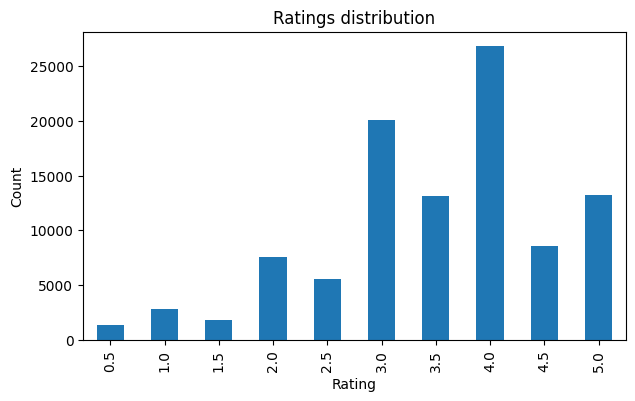

In [ ]:
n_u, n_m = df["user_id"].nunique(), df["item_id"].nunique()
print("Ratings:", len(df), "| Users:", n_u, "| Movies:", n_m)
print(f"Matrix sparsity: {1 - len(df) / (n_u * n_m):.2%}")

df["rating"].value_counts().sort_index().plot(kind="bar", figsize=(7, 4))
plt.xlabel("Rating")
plt.ylabel("Count")
plt.title("Ratings distribution")
plt.show()

## 2. Train/test split and rating matrix

Movie IDs are not contiguous, so IDs are mapped to indices `0..n-1`. The rating matrix is built
from the training set only, so no test rating leaks into any model.

In [ ]:
user_ids = np.sort(df["user_id"].unique())
item_ids = np.sort(df["item_id"].unique())
user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {m: i for i, m in enumerate(item_ids)}
n_users, n_items = len(user_ids), len(item_ids)

df["u"] = df["user_id"].map(user2idx)
df["i"] = df["item_id"].map(item2idx)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)

R = np.full((n_users, n_items), np.nan, dtype=np.float32)   # NaN = unrated
R[train_df["u"].values, train_df["i"].values] = train_df["rating"].values
mask = ~np.isnan(R)

global_mean = np.nanmean(R)
user_mean = np.where(mask.sum(1) > 0, np.nansum(R, 1) / np.maximum(mask.sum(1), 1), global_mean).astype(np.float32)
centered = np.where(mask, R - user_mean[:, None], 0).astype(np.float32)

test_u, test_i = test_df["u"].values, test_df["i"].values
test_y = test_df["rating"].values.astype(np.float32)


def rmse(pred_matrix):
    p = np.clip(pred_matrix[test_u, test_i], 0.5, 5.0)
    return float(np.sqrt(np.mean((p - test_y) ** 2)))


def recommend(pred_matrix, user_id, n=10, min_ratings=10):
    u = user2idx[user_id]
    scores = pred_matrix[u].copy()
    scores[mask[u]] = -np.inf                      # hide already-rated movies
    scores[mask.sum(0) < min_ratings] = -np.inf    # hide obscure movies (noisy scores)
    top = np.argsort(-scores)[:n]
    return pd.DataFrame({
        "movie": [titles.get(item_ids[j], "?") for j in top],
        "predicted_rating": np.clip(scores[top], 0.5, 5.0).round(2),
    })

## 3. Baselines
Users are compared with cosine similarity on their **mean-centred** ratings (so a harsh and a generous
rater with the same taste look similar). A rating is predicted from the `k` most similar users who rated
the movie.

In [ ]:
results = {
    "Global mean": rmse(np.full((n_users, n_items), global_mean)),
    "User mean": rmse(np.tile(user_mean[:, None], (1, n_items))),
}
print(results)

{'Global mean': 1.0488405227661133, 'User mean': 0.9497467875480652}


## 4. User-based collaborative filtering

Cosine similarity on mean-centred ratings; each prediction uses the `k` most similar users.

In [ ]:
def keep_top_k(sim, k):
    """Keep the k largest similarities per row (chunked to save memory)."""
    sim = sim.copy()
    np.fill_diagonal(sim, 0)
    for start in range(0, sim.shape[0], 1000):
        block = sim[start:start + 1000]
        drop = np.argpartition(-block, k, axis=1)[:, k:]
        np.put_along_axis(block, drop, 0, axis=1)
    return sim


K_USER = 30
user_sim = keep_top_k(cosine_similarity(centered).astype(np.float32), K_USER)

num = user_sim @ centered
den = np.abs(user_sim) @ mask.astype(np.float32)
pred_user = user_mean[:, None] + np.divide(num, den, out=np.zeros_like(num), where=den > 0)

results["User-based CF"] = rmse(pred_user)
print("User-based CF RMSE:", round(results["User-based CF"], 4))
recommend(pred_user, user_id=1)

User-based CF RMSE: 0.9257


,movie,predicted_rating
0,"Sex, Lies, and Videotape (1989)",5.0
1,All About My Mother (Todo sobre mi madre) (1999),5.0
2,William Shakespeare's Romeo + Juliet (1996),5.0
3,Hannah and Her Sisters (1986),5.0
4,"Godfather: Part II, The (1974)",5.0
5,Roman Holiday (1953),5.0
6,Blade Runner 2049 (2017),5.0
7,"Wild Bunch, The (1969)",5.0
8,"Secret Life of Walter Mitty, The (2013)",5.0
9,In the Name of the Father (1993),5.0


## 5. Item-based collaborative filtering


Same idea on the item side (adjusted cosine similarity between movies).

In [ ]:
K_ITEM = 30
item_sim = keep_top_k(cosine_similarity(centered.T).astype(np.float32), K_ITEM)

num = centered @ item_sim.T
den = mask.astype(np.float32) @ np.abs(item_sim).T
pred_item = user_mean[:, None] + np.divide(num, den, out=np.zeros_like(num), where=den > 0)
del item_sim

results["Item-based CF"] = rmse(pred_item)
print("Item-based CF RMSE:", round(results["Item-based CF"], 4))
recommend(pred_item, user_id=1)

Item-based CF RMSE: 0.947


,movie,predicted_rating
0,Casino (1995),5.0
1,Nixon (1995),5.0
2,Pocahontas (1995),5.0
3,Cocoon (1985),5.0
4,"Karate Kid, The (1984)",5.0
5,Clue (1985),5.0
6,History of the World: Part I (1981),5.0
7,"Producers, The (1968)",5.0
8,Analyze This (1999),5.0
9,"Thing, The (1982)",5.0


## 6. SVD matrix factorization

Truncated SVD on the mean-centred matrix; the user mean is added back.

In [ ]:
svd = TruncatedSVD(n_components=20, random_state=SEED)
U = svd.fit_transform(centered)
pred_svd = U @ svd.components_ + user_mean[:, None]

results["SVD (k=20)"] = rmse(pred_svd)
print("SVD RMSE:", round(results["SVD (k=20)"], 4))
recommend(pred_svd, user_id=1)

SVD RMSE: 0.9229


,movie,predicted_rating
0,"Shawshank Redemption, The (1994)",4.61
1,"Godfather, The (1972)",4.54
2,Terminator 2: Judgment Day (1991),4.54
3,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),4.52
4,Raiders of the Lost Ark (Indiana Jones and the...,4.50
5,Gattaca (1997),4.50
6,Blade Runner (1982),4.50
7,American History X (1998),4.49
8,"Lord of the Rings: The Return of the King, The...",4.48
9,"Godfather: Part II, The (1974)",4.48


## 7. Neural collaborative filtering (Keras)

User and movie embeddings are concatenated and fed to a small MLP. The output is scaled to the
rating range 0.5-5.0. Early stopping uses a validation split taken from the training data.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)

EMB = 32
user_in = keras.Input(shape=(1,), name="user")
item_in = keras.Input(shape=(1,), name="item")

u_vec = layers.Flatten()(layers.Embedding(n_users, EMB)(user_in))
i_vec = layers.Flatten()(layers.Embedding(n_items, EMB)(item_in))

x = layers.Concatenate()([u_vec, i_vec])
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dense(1, activation="sigmoid")(x)
out = layers.Rescaling(scale=4.5, offset=0.5)(x)   # -> [0.5, 5.0]

ncf = keras.Model([user_in, item_in], out)
ncf.compile(loss="mse", optimizer=keras.optimizers.Adam(1e-3),
            metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
ncf.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ item (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 32)     │     19,520 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 32)     │    311,168 │ item[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      8,320 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 1)         │          0 │ dense_2[0][0]     │
│ (Rescaling)         │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 347,329 (1.32 MB)

 Trainable params: 347,329 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
284/284 - 8s - 27ms/step - loss: 0.8776 - rmse: 0.9368 - val_loss: 0.7988 - val_rmse: 0.8938
Epoch 2/30
284/284 - 5s - 18ms/step - loss: 0.7098 - rmse: 0.8425 - val_loss: 0.7758 - val_rmse: 0.8808
Epoch 3/30
284/284 - 6s - 21ms/step - loss: 0.6463 - rmse: 0.8039 - val_loss: 0.7855 - val_rmse: 0.8863
Epoch 4/30
284/284 - 6s - 23ms/step - loss: 0.5968 - rmse: 0.7725 - val_loss: 0.8060 - val_rmse: 0.8978
Epoch 5/30
284/284 - 3s - 12ms/step - loss: 0.5611 - rmse: 0.7491 - val_loss: 0.8206 - val_rmse: 0.9059


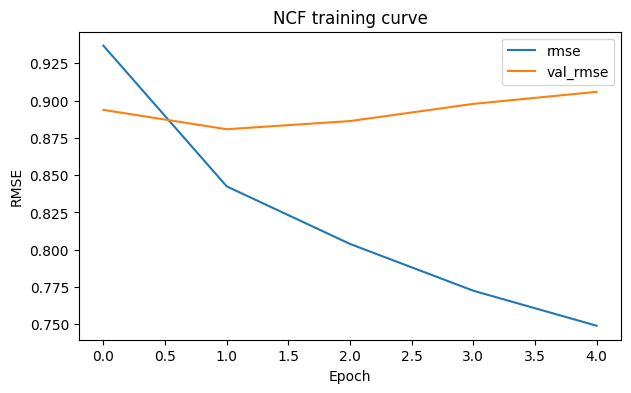

In [ ]:
history = ncf.fit(
    [train_df["u"].values, train_df["i"].values],
    train_df["rating"].values.astype("float32"),
    batch_size=256,
    epochs=30,
    validation_split=0.1,
    callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=2,
)

pd.DataFrame(history.history)[["rmse", "val_rmse"]].plot(figsize=(7, 4), title="NCF training curve")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.show()

In [ ]:
uu, ii = np.meshgrid(np.arange(n_users), np.arange(n_items), indexing="ij")
pred_ncf = ncf.predict([uu.ravel(), ii.ravel()], batch_size=8192, verbose=0).reshape(n_users, n_items)

results["Neural CF"] = rmse(pred_ncf)
print("Neural CF RMSE:", round(results["Neural CF"], 4))

ncf.save("recommender_model.keras")
recommend(pred_ncf, user_id=1)

Neural CF RMSE: 0.8805


,movie,predicted_rating
0,"Godfather, The (1972)",4.80
1,"Hustler, The (1961)",4.78
2,"Philadelphia Story, The (1940)",4.77
3,Rear Window (1954),4.77
4,"Grand Day Out with Wallace and Gromit, A (1989)",4.75
5,"Shawshank Redemption, The (1994)",4.75
6,Yojimbo (1961),4.75
7,Secrets & Lies (1996),4.75
8,Double Indemnity (1944),4.75
9,Touch of Evil (1958),4.75


## 8. Simple hybrid and comparison

The hybrid averages the four model predictions.

Hybrid (average)    0.8652
Neural CF           0.8805
SVD (k=20)          0.9229
User-based CF       0.9257
Item-based CF       0.9470
User mean           0.9497
Global mean         1.0488
dtype: float64


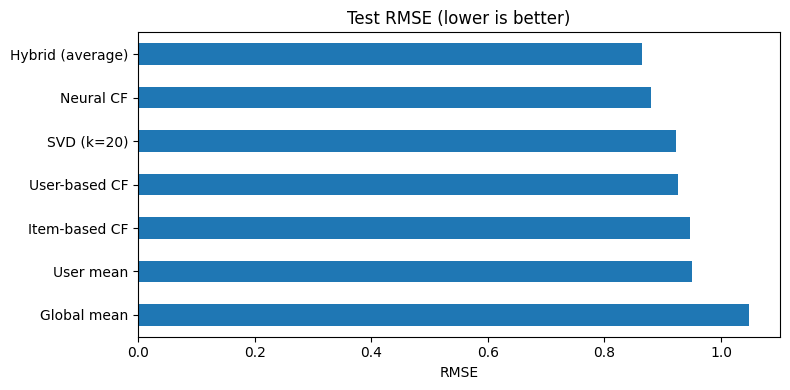

In [ ]:
pred_hybrid = (pred_user + pred_item + pred_svd + pred_ncf) / 4
results["Hybrid (average)"] = rmse(pred_hybrid)

res = pd.Series(results).sort_values()
print(res.round(4))

res.plot(kind="barh", figsize=(8, 4), title="Test RMSE (lower is better)")
plt.gca().invert_yaxis()
plt.xlabel("RMSE")
plt.tight_layout()
plt.show()

In [ ]:
print("Top 10 hybrid recommendations for user 1:")
recommend(pred_hybrid, user_id=1)

Top 10 hybrid recommendations for user 1:


,movie,predicted_rating
0,All About My Mother (Todo sobre mi madre) (1999),5.00
1,William Shakespeare's Romeo + Juliet (1996),5.00
2,"Sex, Lies, and Videotape (1989)",5.00
3,"Godfather: Part II, The (1974)",4.97
4,Unforgiven (1992),4.92
5,Equilibrium (2002),4.88
6,Drive (2011),4.87
7,"Shawshank Redemption, The (1994)",4.86
8,Thirteen Days (2000),4.85
9,"Boondock Saints, The (2000)",4.85


## results
Dataset: MovieLens ml-latest-small (100,836 ratings, 610 users, 9,724 movies, 98.3% sparse). Fixed 80/20 split (seed 42), evaluated by test RMSE.

Model	Test RMSE

| Model | Test RMSE |
|---|---|
| Global mean | 1.049 |
| User mean | 0.950 |
| User-based CF (k=30) | 0.926 |
| Item-based CF (k=30) | 0.947 |
| SVD (20 components) | **0.923** |
| Neural CF | - |
| Hybrid (average) | - |


SVD is the best model so far (0.923), with user-based CF close behind (0.926).
Every model beats the baselines, but only by about 3% over user mean.
Item-based CF barely beats the baseline, likely because the data is so sparse.

